# QCoDeS example with Keithley 2280S

The [Keithley 2280S](https://www.tek.com/en/products/dc-power-supplies/2280s-series) is a bench power supply with measurement capability. This notebook shows how to connect to the instrument and set and read voltage.

The instrument comes in two variants. This notebook was tested with the variant 2280S-32-6.

## Connect to the instrument
1. Make sure you have QCoDeS set up (see the [QCoDeS website](https://microsoft.github.io/Qcodes/index.html) or my notebook [14 minutes to QCoDeS](https://github.com/lairdgrouplancaster/14-minutes-to-QCoDeS/blob/main/14_minutes_to_QCoDeS.ipynb)).
2. Connect the instrument by USB. Set the USB address in the first cell below.
3. A good testing configuration is to connect the + and - terminals on the front by a 50 Ohm terminator. **Take care that you do not exceed the power rating of the terminator during tests.** The settings below do not dissipate more than 5 mW nominal, whereas a typical rating is 500 mW, so this notebook should be safe to run.

In [1]:
from qcodes_contrib_drivers.drivers.Tektronix.keithley_2280s import Keithley2280S

address = "USB0::0x05E6::0x2280::4496881::INSTR"
supply = Keithley2280S("supply", address, reset=True, timeout=10)
supply.IDN()

Connected to: KEITHLEY INSTRUMENTS 2280S-32-6 (serial:4496881, firmware:01.07b) in 1.22s


{'vendor': 'KEITHLEY INSTRUMENTS',
 'model': '2280S-32-6',
 'serial': '4496881',
 'firmware': '01.07b'}

## Initialise QCoDeS control
Station and experiment setup:

In [2]:
from pathlib import Path

from qcodes import config
from qcodes.station import Station
from qcodes.dataset import (
    do1d,
    initialise_or_create_database_at,
    load_or_create_experiment,
)

station = Station(supply)
data_directory = Path.home() / "qcodes_data" / "keithley_tests"
data_directory.mkdir(parents=True, exist_ok=True)
config.user.mainfolder = str(data_directory)  # Destination for saved plots.
initialise_or_create_database_at(str(data_directory / "keithley_tests.db"))
experiment = load_or_create_experiment(
    experiment_name="Keithley 2280S examples",
    sample_name="terminator",
)

print("Data written to:", Path(config.core.db_location).resolve())

Data written to: C:\Users\lairde\qcodes_data\keithley_tests\keithley_tests.db


## Set and read individual parameters

In [3]:
#Turn the output off
supply.output("off")

In [4]:
#Read the output status
supply.output()

'off'

In [5]:
# Set up measurements
supply.autozero(True)       # Autozero: better accuracy, slightly slower measurements.
supply.continuous(True)     # Continuous triggering

supply.data_format("READ, SOUR")    # Read both the measured value and the source value, but not unit or range information.

for sense in (supply.voltage, supply.current, supply.concurrent):
    sense.nplc(1)                   # One power line cycle averaging
    sense.digits(6)
    sense.filter_enabled(False)
    sense.relative_enabled(False)

In [6]:
# Set voltage, measure current:
supply.source_current(0.01)  # Current limit: 10 mA. This is called I-Limit on the front panel.
supply.current.range(0.01)   # Fixed 10 mA measurement range
supply.source_voltage(0.1)   # Voltage setpoint: 100 mV. This is called V-Set on the front panel.

supply.output("on")
supply.current.measure()    # Should be close to 2 mA, since the terminator is 50 ohms.

0.002010157

In [7]:
# Set current, measure voltage:
supply.voltage_limit(2)     # Allow voltage settings up to 2 V
supply.source_voltage(1)    # Voltage ceiling: 1 V
supply.source_current(0.01) # Desired current: 10 mA

supply.voltage.measure()    # Should be close to 0.5 V across 50 ohms

0.5117534

In [8]:
# Measure both:
supply.concurrent.measure()

(0.01023348, 0.5112486)

## Run sweeps
Use `do1d()` to acquire point-by-point sweeps.
### Sweep voltage, measure current

In [9]:
# Set up, to ensure limits are high enough to run the sweep.
supply.source_voltage(0)    
supply.voltage_limit(1)   # Allow voltage settings up to 1 V
supply.source_current(0.01) # Current limit: 10 mA
supply.current.autorange(True)

Starting experimental run with id: 23. Using 'qcodes.dataset.do1d'


(results #23@C:\Users\lairde\qcodes_data\keithley_tests\keithley_tests.db
 ------------------------------------------------------------------------
 supply_source_voltage - numeric
 supply_current_measure - numeric,
 (<Axes: title={'center': 'Run #23, Experiment Keithley 2280S examples (terminator)'}, xlabel='Source voltage (mV)', ylabel='Measured current (mA)'>,),
 (None,))

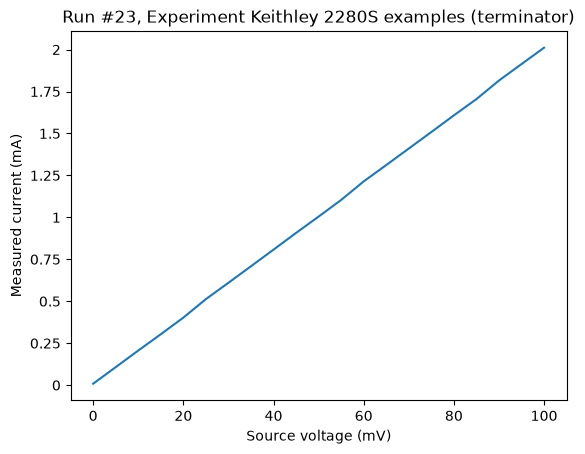

In [10]:
# Run the sweep.
do1d(supply.source_voltage, 0, 0.1, 21, 0.1, supply.current.measure, write_period=0.1, do_plot=True)

### Sweep current, measure voltage
A peculiarity of the interface is that the source current parameter is called I-Limit on the front panel. So the way to sweep current is to set the source voltage (called V-Set) to a value higher than the expected voltage (but still a safe value for your sample) and then sweep I-Limit.

In [11]:

# Set up, to ensure limits are high enough to run the sweep.
supply.source_current(0)    # Start with a low current setting before raising voltage ceiling.
supply.voltage_limit(1)   # Allow voltage settings up to 1 V
supply.source_voltage(0.9)  # Actual voltage ceiling during the current sweep
supply.concurrent.autorange(True)

Starting experimental run with id: 24. Using 'qcodes.dataset.do1d'


(results #24@C:\Users\lairde\qcodes_data\keithley_tests\keithley_tests.db
 ------------------------------------------------------------------------
 supply_source_current - numeric
 supply_concurrent_voltage - numeric,
 (<Axes: title={'center': 'Run #24, Experiment Keithley 2280S examples (terminator)'}, xlabel='Current limit (mA)', ylabel='Measured voltage (mV)'>,),
 (None,))

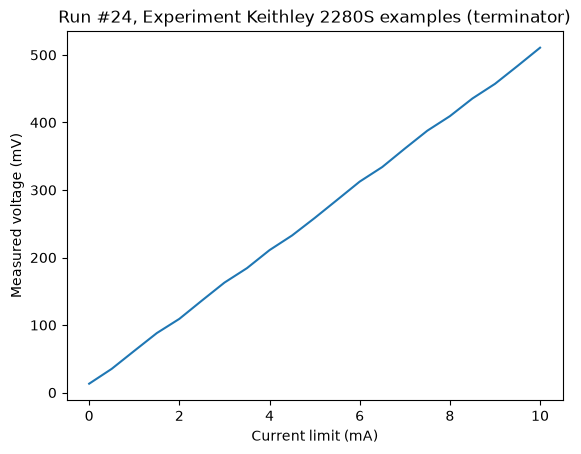

In [12]:
# Run the sweep.
do1d(supply.source_current, 0, 0.01, 21, 0.1, supply.concurrent.voltage, write_period=0.1, do_plot=True)

## Finish
Disable the output, set the instrument back to local control and close the connection

In [13]:
supply.output("off")
supply.local()
supply.close()